# Evaluacion Parcial Nro 2 - Deep Learning - DUOC UC
## 2do semestre 2026
----

## Integrantes del Grupo
----

- Esteban Gamboa
- Felipe Ortega
## **Importante: La entrega se debe realizar mediante GitHub**

## Convolutional Neural Networks

En esta actividad, vamos a trabajar con Convolutional Neural Networks para resolver un problema de clasificación de imágenes. En particular, vamos a clasificar imágenes de personajes de la conocida serie de los Simpsons.

Como las CNN profundas son un tipo de modelo bastante avanzado y computacionalmente costoso, se recomienda hacer la práctica en Google Colaboratory con soporte para GPUs. En [este enlace](https://medium.com/deep-learning-turkey/google-colab-free-gpu-tutorial-e113627b9f5d) se explica cómo activar un entorno con GPUs. *Nota: para leer las imágenes y estandarizarlas al mismo tamaño se usa la librería opencv. Esta ĺibrería está ya instalada en el entorno de Colab. (Si trabajan de manera local deberán instalarla)*

<center><img src="https://i.imgur.com/i8zIGqX.jpg" style="text-align: center" height="300px"></center>

El dataset a utilizar consiste en imágenes de personajes de los Simpsons extraídas directamente de capítulos de la serie. Este dataset ha sido recopilado por [Alexandre Attia](http://www.alexattia.fr/) y es más complejo que el dataset de Fashion MNIST que hemos utilizado hasta ahora. Aparte de tener más clases (vamos a utilizar los 18 personajes con más imágenes), los personajes pueden aparecer en distintas poses, en distintas posiciones de la imagen o con otros personajes en pantalla (si bien el personaje a clasificar siempre aparece en la posición predominante).

El dataset de training puede ser descargado desde aquí:

[Training data](https://onedrive.live.com/download?cid=C506CF0A4F373B0F&resid=C506CF0A4F373B0F%219337&authkey=AMzI92bJPx8Sd60) (~500MB)

Por otro lado, el dataset de test puede ser descargado de aquí:

[Test data](https://onedrive.live.com/download?cid=C506CF0A4F373B0F&resid=C506CF0A4F373B0F%219341&authkey=ANnjK3Uq1FhuAe8) (~10MB)

Antes de empezar la práctica, se recomienda descargar las imágenes y echarlas un vistazo.


## Carga de los datos

In [ ]:
import os, glob, itertools, collections, random
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

import tensorflow as tf
import keras
from keras import layers, models, optimizers, callbacks

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, precision_recall_fscore_support
from sklearn.utils.class_weight import compute_class_weight

# Reproducibilidad
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
print("GPUs disponibles:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0 | Keras: 3.13.2
GPUs disponibles: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# Carpeta de Drive donde subiste los archivos
DRIVE_DIR = "/content/drive/MyDrive/eva 2 deep learning"

# Descomprimimos en el disco local de Colab (mucho más rápido que leer desde Drive)
!mkdir -p /content/data
!tar -xzf "{DRIVE_DIR}/simpsons_train.tar.gz" -C /content/data
!tar -xzf "{DRIVE_DIR}/simpsons_test.tar.gz" -C /content/data

!ls /content/data

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
tar (child): /content/drive/MyDrive/eva 2 deep learning/simpsons_train.tar.gz: Cannot open: No such file or directory
tar (child): Error is not recoverable: exiting now
tar: Child returned status 2
tar: Error is not recoverable: exiting now
tar (child): /content/drive/MyDrive/eva 2 deep learning/simpsons_test.tar.gz: Cannot open: No such file or directory
tar (child): Error is not recoverable: exiting now
tar: Child returned status 2
tar: Error is not recoverable: exiting now


In [ ]:
# Esta variable contiene un mapeo de número de clase a personaje.
# Utilizamos sólo los 18 personajes del dataset que tienen más imágenes.
MAP_CHARACTERS = {
    0: 'abraham_grampa_simpson', 1: 'apu_nahasapeemapetilon', 2: 'bart_simpson',
    3: 'charles_montgomery_burns', 4: 'chief_wiggum', 5: 'comic_book_guy', 6: 'edna_krabappel',
    7: 'homer_simpson', 8: 'kent_brockman', 9: 'krusty_the_clown', 10: 'lisa_simpson',
    11: 'marge_simpson', 12: 'milhouse_van_houten', 13: 'moe_szyslak',
    14: 'ned_flanders', 15: 'nelson_muntz', 16: 'principal_skinner', 17: 'sideshow_bob'
}

# Vamos a standarizar todas las imágenes a tamaño 64x64
IMG_SIZE = 64

In [ ]:
def load_train_set(dirname, map_characters, verbose=True):

    X_train = []
    y_train = []
    for label, character in map_characters.items():
        files = os.listdir(os.path.join(dirname, character))
        images = [file for file in files if file.endswith("jpg")]
        if verbose:
          print("Leyendo {} imágenes encontradas de {}".format(len(images), character))
        for image_name in images:
            image = cv2.imread(os.path.join(dirname, character, image_name))
            X_train.append(cv2.resize(image,(IMG_SIZE, IMG_SIZE)))
            y_train.append(label)
    return np.array(X_train), np.array(y_train)

In [ ]:
def load_test_set(dirname, map_characters, verbose=True):
    """Esta función funciona de manera equivalente a la función load_train_set
    pero cargando los datos de test."""
    X_test = []
    y_test = []
    reverse_dict = {v: k for k, v in map_characters.items()}
    for filename in glob.glob(dirname + '/*.*'):
        char_name = "_".join(filename.split('/')[-1].split('_')[:-1])
        if char_name in reverse_dict:
            image = cv2.imread(filename)
            image = cv2.resize(image, (IMG_SIZE, IMG_SIZE))
            X_test.append(image)
            y_test.append(reverse_dict[char_name])
    if verbose:
        print("Leídas {} imágenes de test".format(len(X_test)))
    return np.array(X_test), np.array(y_test)


In [ ]:
import os, glob, tarfile
import cv2
import numpy as np

from google.colab import drive
drive.mount('/content/drive')

def buscar_archivo(nombre):
    for base in ["/content/drive/MyDrive", "/content/drive/Shareddrives",
                 "/content/drive/.shortcut-targets-by-id", "/content/drive"]:
        if os.path.exists(base):
            encontrados = glob.glob(os.path.join(base, "**", nombre), recursive=True)
            if encontrados:
                return encontrados[0]
    return None

RUTA_TRAIN_TAR = buscar_archivo("simpsons_train.tar.gz")
RUTA_TEST_TAR  = buscar_archivo("simpsons_test.tar.gz")
print("Train tar:", RUTA_TRAIN_TAR)
print("Test tar :", RUTA_TEST_TAR)

if RUTA_TRAIN_TAR is None or RUTA_TEST_TAR is None:
    print("\n No se encontraron. Carpetas en tu Drive:")
    print(os.listdir("/content/drive/MyDrive"))
    raise FileNotFoundError("Revisa el listado de arriba y dime cómo se llama la carpeta")


DESTINO = "/root/.keras/datasets"
os.makedirs(DESTINO, exist_ok=True)
for ruta in [RUTA_TRAIN_TAR, RUTA_TEST_TAR]:
    marca = os.path.join(DESTINO, os.path.basename(ruta) + ".ok")
    if not os.path.exists(marca):
        print("Extrayendo", os.path.basename(ruta), "...")
        with tarfile.open(ruta, "r:gz") as tar:
            tar.extractall(DESTINO)
        open(marca, "w").close()
print("Contenido:", os.listdir(DESTINO))

def buscar_carpetas(raiz):
    dir_train, dir_test = None, None
    for actual, subdirs, archivos in os.walk(raiz):
        if dir_train is None and "homer_simpson" in subdirs:
            dir_train = actual
        if dir_test is None and any(a.startswith("homer_simpson_") and a.endswith(".jpg") for a in archivos):
            dir_test = actual
    return dir_train, dir_test

DATASET_TRAIN_PATH_COLAB, DATASET_TEST_PATH_COLAB = buscar_carpetas(DESTINO)
print("Train:", DATASET_TRAIN_PATH_COLAB)
print("Test :", DATASET_TEST_PATH_COLAB)

def load_train_set(dirname, map_characters, verbose=True):
    X_train, y_train = [], []
    for label, character in map_characters.items():
        files = glob.glob(os.path.join(dirname, character, "*.jpg"))
        for f in files:
            image = cv2.imread(f)
            if image is None:
                continue
            X_train.append(cv2.resize(image, (IMG_SIZE, IMG_SIZE)))
            y_train.append(label)
        if verbose:
            print("Leídas {} imágenes de {}".format(len(files), character))
    return np.array(X_train), np.array(y_train)

def load_test_set(dirname, map_characters, verbose=True):
    X_test, y_test = [], []
    reverse_dict = {v: k for k, v in map_characters.items()}
    for filename in glob.glob(os.path.join(dirname, "*.*")):
        char_name = "_".join(os.path.basename(filename).split('_')[:-1])
        if char_name in reverse_dict:
            image = cv2.imread(filename)
            if image is None:
                continue
            X_test.append(cv2.resize(image, (IMG_SIZE, IMG_SIZE)))
            y_test.append(reverse_dict[char_name])
    if verbose:
        print("Leídas {} imágenes de test".format(len(X_test)))
    return np.array(X_test), np.array(y_test)

X, y = load_train_set(DATASET_TRAIN_PATH_COLAB, MAP_CHARACTERS)
X_t, y_t = load_test_set(DATASET_TEST_PATH_COLAB, MAP_CHARACTERS)
print(X.shape, X_t.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Train tar: /content/drive/MyDrive/eva 2 deep learning /simpsons_train.tar.gz
Test tar : /content/drive/MyDrive/eva 2 deep learning /simpsons_test.tar.gz
Extrayendo simpsons_train.tar.gz ...


/tmp/ipykernel_1989/239966137.py:35: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(DESTINO)


Extrayendo simpsons_test.tar.gz ...
Contenido: ['simpsons_train.tar.gz.ok', 'simpsons_test.tar.gz.ok', 'simpsons', 'simpsons_testset']
Train: /root/.keras/datasets/simpsons
Test : /root/.keras/datasets/simpsons_testset
Leídas 913 imágenes de abraham_grampa_simpson
Leídas 623 imágenes de apu_nahasapeemapetilon
Leídas 1342 imágenes de bart_simpson
Leídas 1193 imágenes de charles_montgomery_burns
Leídas 986 imágenes de chief_wiggum
Leídas 469 imágenes de comic_book_guy
Leídas 457 imágenes de edna_krabappel
Leídas 2246 imágenes de homer_simpson
Leídas 498 imágenes de kent_brockman
Leídas 1206 imágenes de krusty_the_clown
Leídas 1354 imágenes de lisa_simpson
Leídas 1291 imágenes de marge_simpson
Leídas 1079 imágenes de milhouse_van_houten
Leídas 1452 imágenes de moe_szyslak
Leídas 1454 imágenes de ned_flanders
Leídas 358 imágenes de nelson_muntz
Leídas 1194 imágenes de principal_skinner
Leídas 877 imágenes de sideshow_bob
Leídas 890 imágenes de test
(18992, 64, 64, 3) (890, 64, 64, 3)


In [ ]:
# Vamos a barajar aleatoriamente los datos. Esto es importante ya que si no
# lo hacemos y, por ejemplo, cogemos el 20% de los datos finales como validation
# set, estaremos utilizando solo un pequeño número de personajes, ya que
# las imágenes se leen secuencialmente personaje a personaje.
perm = np.random.permutation(len(X))
X, y = X[perm], y[perm]

## Entregable

Utilizando Convolutional Neural Networks con Keras, entrenar un clasificador que sea capaz de reconocer personajes en imágenes de los Simpsons con una accuracy en el dataset de test de al menos **85%**. Presentar un notebook analizando las alternativas probadas y los resultados obtenidos.

A continuación se detallan una serie de aspectos orientativos que podrían ser analizados en el informe (no es necesario tratar todos ellos):

*   Análisis de los datos a utilizar.
*   Análisis de resultados, obtención de métricas de *precision* y *recall* por clase y análisis de qué clases obtienen mejores o peores resultados.
*   Análisis visual de los errores de la red. ¿Qué tipo de imágenes o qué personajes dan más problemas a nuestro modelo?
*   Comparación de modelos CNNs con un modelo de Fully Connected para este problema.
*   Utilización de distintas arquitecturas CNNs, comentando aspectos como su profundidad, hiperparámetros utilizados, optimizador, uso de técnicas de regularización, *batch normalization*, etc.
*   [ *algo más difícil* ] Utilización de *data augmentation*. Esto puede conseguirse con la clase [ImageDataGenerator](https://keras.io/preprocessing/image/#imagedatagenerator-class) de Keras.

Notas:
* Recuerda partir los datos en training/validation para tener una buena estimación de los valores que nuestro modelo tendrá en los datos de test, así como comprobar que no estamos cayendo en overfitting. Una posible partición puede ser 80 / 20.
* No es necesario mostrar en el notebook las trazas de entrenamiento de todos los modelos entrenados, si bien una buena idea seria guardar gráficas de esos entrenamientos para el análisis. Sin embargo, **se debe mostrar el entrenamiento completo del mejor modelo obtenido y la evaluación de los datos de test con este modelo**.
* Las imágenes **no están normalizadas**. Hay que normalizarlas.
* El test set del problema tiene imágenes un poco más "fáciles", por lo que es posible encontrarse con métricas en el test set bastante mejores que en el training set.

## 1. Análisis de los datos

Antes de entrenar revisamos cómo están distribuidas las clases y qué aspecto tienen las imágenes.

X (train): (18992, 64, 64, 3) uint8 | y: (18992,)
X_t (test): (890, 64, 64, 3) uint8 | y_t: (890,)
Rango de píxeles: 0 - 255


,personaje,train,test,% train
0,homer_simpson,2246,50,11.83
1,ned_flanders,1454,49,7.66
2,moe_szyslak,1452,50,7.65
3,lisa_simpson,1354,50,7.13
4,bart_simpson,1342,50,7.07
5,marge_simpson,1291,50,6.80
6,krusty_the_clown,1206,50,6.35
7,principal_skinner,1194,50,6.29
8,charles_montgomery_burns,1193,48,6.28
9,milhouse_van_houten,1079,49,5.68


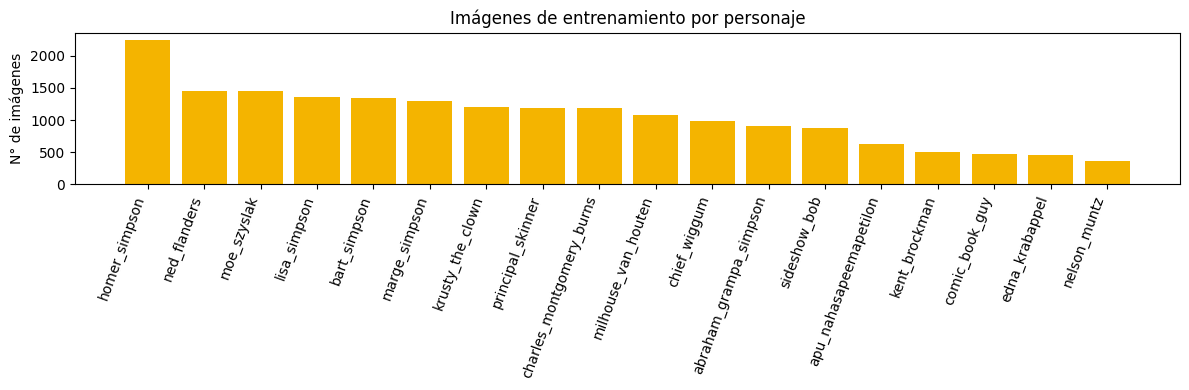

Razón clase mayoritaria / minoritaria: 6.3x


In [ ]:
print("X (train):", X.shape, X.dtype, "| y:", y.shape)
print("X_t (test):", X_t.shape, X_t.dtype, "| y_t:", y_t.shape)
print("Rango de píxeles:", X.min(), "-", X.max())

nombres = [MAP_CHARACTERS[i] for i in range(len(MAP_CHARACTERS))]
conteo_train = np.bincount(y, minlength=18)
conteo_test = np.bincount(y_t, minlength=18)

df_dist = pd.DataFrame({"personaje": nombres, "train": conteo_train, "test": conteo_test})
df_dist["% train"] = (100 * df_dist["train"] / df_dist["train"].sum()).round(2)
display(df_dist.sort_values("train", ascending=False).reset_index(drop=True))

fig, ax = plt.subplots(figsize=(12, 4))
orden = np.argsort(-conteo_train)
ax.bar([nombres[i] for i in orden], conteo_train[orden], color="#f4b400")
ax.set_title("Imágenes de entrenamiento por personaje")
ax.set_ylabel("N° de imágenes")
plt.xticks(rotation=70, ha="right")
plt.tight_layout(); plt.show()

print(f"Razón clase mayoritaria / minoritaria: {conteo_train.max() / conteo_train.min():.1f}x")

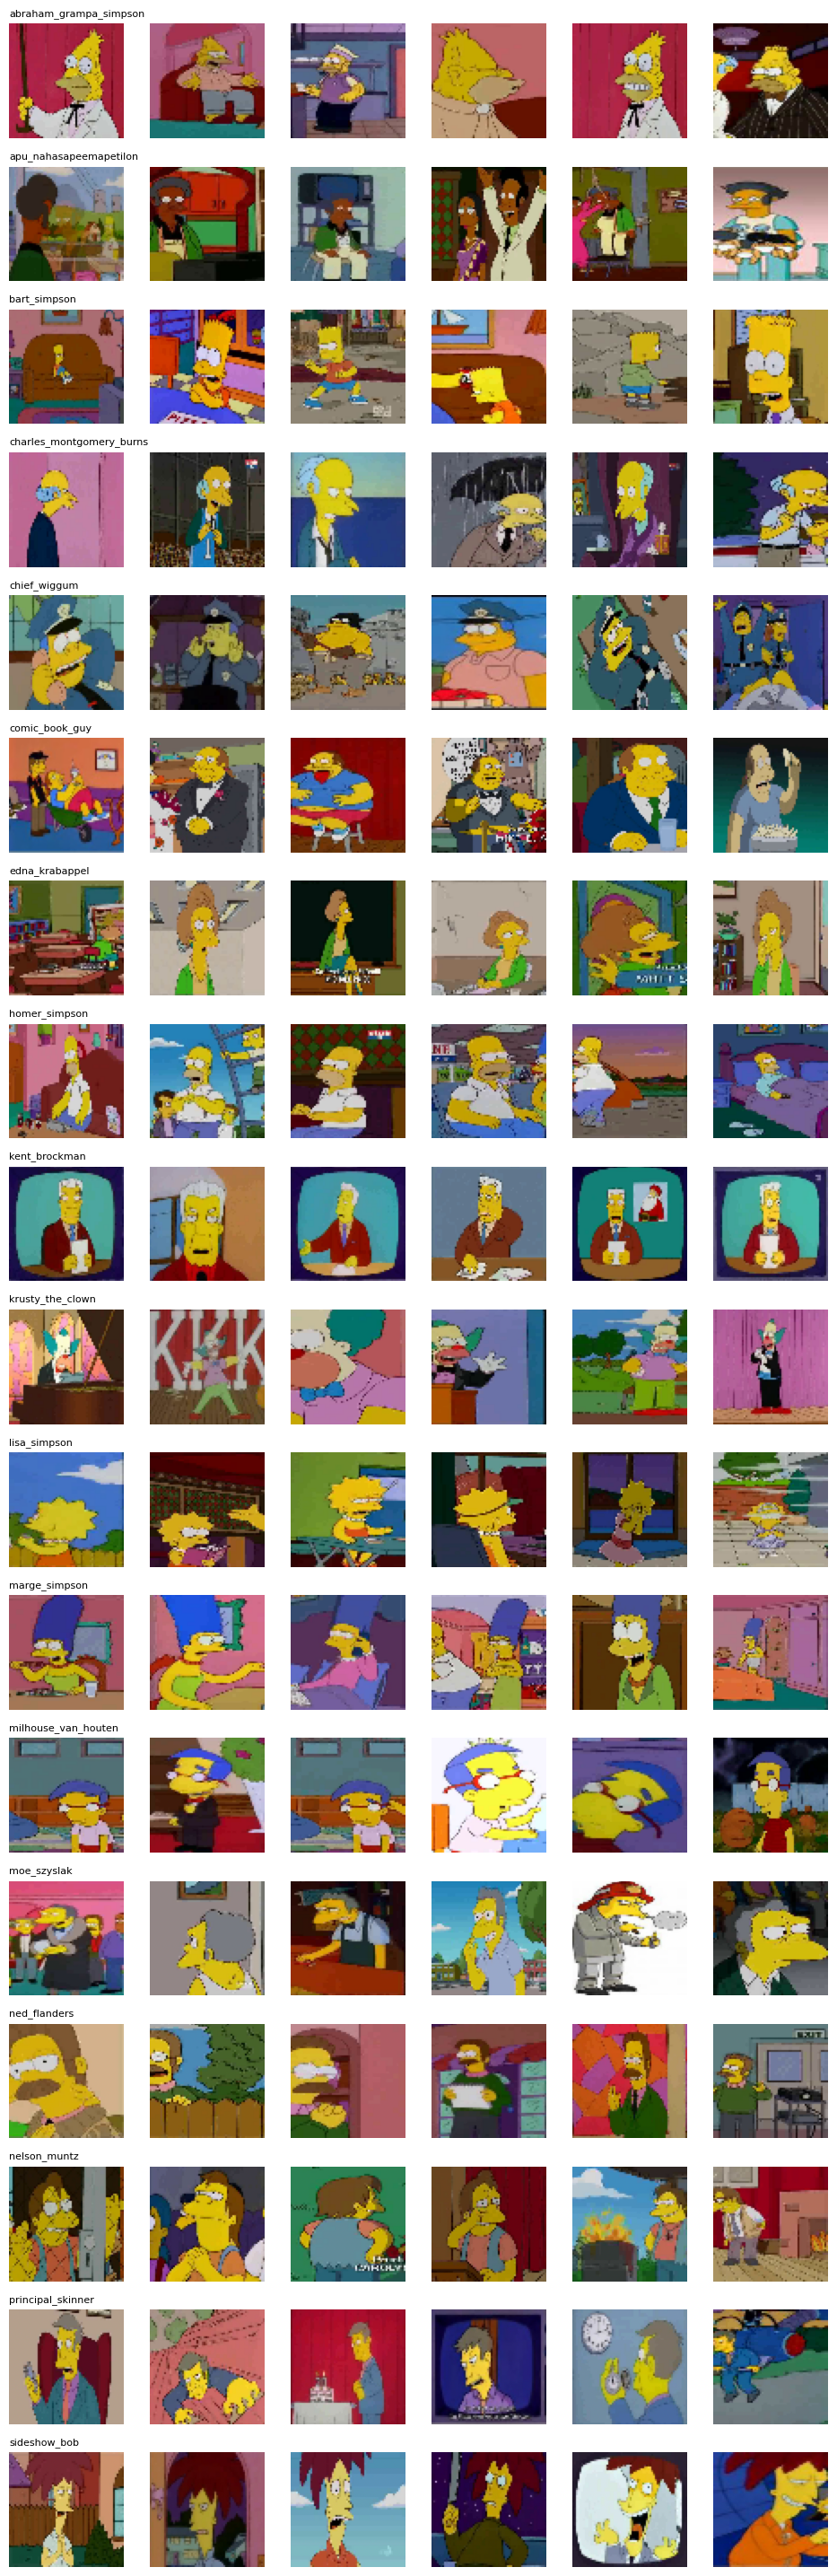

In [ ]:
# Muestra de imágenes (una fila por cuatro personajes). OpenCV carga en BGR -> convertimos a RGB para mostrar.
def mostrar_ejemplos(X, y, n_por_clase=6):
    fig, axes = plt.subplots(18, n_por_clase, figsize=(n_por_clase * 1.6, 18 * 1.6))
    for c in range(18):
        idx = np.where(y == c)[0][:n_por_clase]
        for j in range(n_por_clase):
            ax = axes[c, j]
            ax.imshow(cv2.cvtColor(X[idx[j]].astype("uint8"), cv2.COLOR_BGR2RGB))
            ax.axis("off")
            if j == 0:
                ax.set_title(MAP_CHARACTERS[c], fontsize=8, loc="left")
    plt.tight_layout(); plt.show()

mostrar_ejemplos(X, y)

**Observaciones sobre los datos**

- El dataset está **desbalanceado**: Homer tiene muchas más imágenes que personajes como Nelson o Comic Book Guy. Esto puede sesgar al modelo hacia las clases grandes, por lo que más adelante se usan `class_weight` y se evalúa con *precision* / *recall* por clase y no solo con accuracy.
- Las imágenes vienen de capítulos de la serie, con **distintas poses, fondos y otros personajes** en pantalla, y se redimensionan a 64×64 (se pierde algo de detalle).
- Los valores de píxel están en el rango 0–255, por lo que **deben normalizarse**.

## 2. Preprocesamiento: normalización y partición train / validation

Normalizamos los píxeles a [0, 1] y separamos un 20 % para validación (partición **estratificada**, para mantener la proporción de cada personaje).
El test set se usa **solo** para la evaluación final.

In [ ]:
# Normalización a [0, 1]
X_norm = X.astype("float32") / 255.0
X_test = X_t.astype("float32") / 255.0

# Partición 80 / 20 estratificada
X_train, X_val, y_train, y_val = train_test_split(
    X_norm, y, test_size=0.20, stratify=y, random_state=SEED
)
y_test = y_t

print("Train:", X_train.shape, "| Val:", X_val.shape, "| Test:", X_test.shape)

# Pesos por clase para compensar el desbalance
pesos = compute_class_weight("balanced", classes=np.arange(18), y=y_train)
CLASS_WEIGHT = {i: float(w) for i, w in enumerate(pesos)}
print({MAP_CHARACTERS[i]: round(w, 2) for i, w in CLASS_WEIGHT.items()})

NUM_CLASSES = 18
INPUT_SHAPE = (IMG_SIZE, IMG_SIZE, 3)
BATCH_SIZE = 64

Train: (15193, 64, 64, 3) | Val: (3799, 64, 64, 3) | Test: (890, 64, 64, 3)
{'abraham_grampa_simpson': 1.16, 'apu_nahasapeemapetilon': 1.69, 'bart_simpson': 0.79, 'charles_montgomery_burns': 0.88, 'chief_wiggum': 1.07, 'comic_book_guy': 2.25, 'edna_krabappel': 2.31, 'homer_simpson': 0.47, 'kent_brockman': 2.12, 'krusty_the_clown': 0.87, 'lisa_simpson': 0.78, 'marge_simpson': 0.82, 'milhouse_van_houten': 0.98, 'moe_szyslak': 0.73, 'ned_flanders': 0.73, 'nelson_muntz': 2.95, 'principal_skinner': 0.88, 'sideshow_bob': 1.2}


In [ ]:
# Épocas (ajustables). Con GPU en Colab el entrenamiento completo toma pocos minutos.
EPOCHS_COMPARE = 15   # modelos de comparación
EPOCHS_BEST = 60      # modelo final (con EarlyStopping)

resultados = {}   # nombre -> dict con métricas
historias = {}    # nombre -> History

def graficar_historia(hist, titulo):
    h = hist.history
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(h["accuracy"], label="train"); ax[0].plot(h["val_accuracy"], label="val")
    ax[0].set_title(f"{titulo} - Accuracy"); ax[0].set_xlabel("época"); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].plot(h["loss"], label="train"); ax[1].plot(h["val_loss"], label="val")
    ax[1].set_title(f"{titulo} - Loss"); ax[1].set_xlabel("época"); ax[1].legend(); ax[1].grid(alpha=.3)
    plt.tight_layout(); plt.show()

def registrar(nombre, modelo, hist):
    """Guarda métricas de train / val / test del modelo."""
    historias[nombre] = hist
    _, acc_tr = modelo.evaluate(X_train, y_train, verbose=0, batch_size=256)
    _, acc_val = modelo.evaluate(X_val, y_val, verbose=0, batch_size=256)
    _, acc_te = modelo.evaluate(X_test, y_test, verbose=0, batch_size=256)
    resultados[nombre] = {"parámetros": modelo.count_params(),
                          "acc train": acc_tr, "acc val": acc_val, "acc test": acc_te}
    print(f"{nombre}: train={acc_tr:.4f} | val={acc_val:.4f} | test={acc_te:.4f}")

## 3. Modelo base: red Fully Connected (MLP)

Primero una red densa que ve la imagen como un vector de 64·64·3 valores, para comparar contra las CNN.

Model: "MLP"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     6,291,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 18)             │         4,626 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,427,922 (24.52 MB)

 Trainable params: 6,427,922 (24.52 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
238/238 - 9s - 36ms/step - accuracy: 0.1114 - loss: 2.9993 - val_accuracy: 0.1287 - val_loss: 2.7222
Epoch 2/15
238/238 - 1s - 6ms/step - accuracy: 0.1231 - loss: 2.7312 - val_accuracy: 0.1872 - val_loss: 2.6101
Epoch 3/15
238/238 - 1s - 5ms/step - accuracy: 0.1365 - loss: 2.7026 - val_accuracy: 0.2072 - val_loss: 2.6060
Epoch 4/15
238/238 - 1s - 5ms/step - accuracy: 0.1405 - loss: 2.6895 - val_accuracy: 0.2074 - val_loss: 2.5912
Epoch 5/15
238/238 - 1s - 5ms/step - accuracy: 0.1501 - loss: 2.6783 - val_accuracy: 0.2106 - val_loss: 2.5974
Epoch 6/15
238/238 - 1s - 5ms/step - accuracy: 0.1482 - loss: 2.6658 - val_accuracy: 0.2085 - val_loss: 2.5641
Epoch 7/15
238/238 - 1s - 5ms/step - accuracy: 0.1497 - loss: 2.6617 - val_accuracy: 0.2174 - val_loss: 2.5602
Epoch 8/15
238/238 - 1s - 5ms/step - accuracy: 0.1409 - loss: 2.6822 - val_accuracy: 0.1637 - val_loss: 2.6840
Epoch 9/15
238/238 - 1s - 6ms/step - accuracy: 0.1521 - loss: 2.6596 - val_accuracy: 0.2072 - val_loss: 2.5911


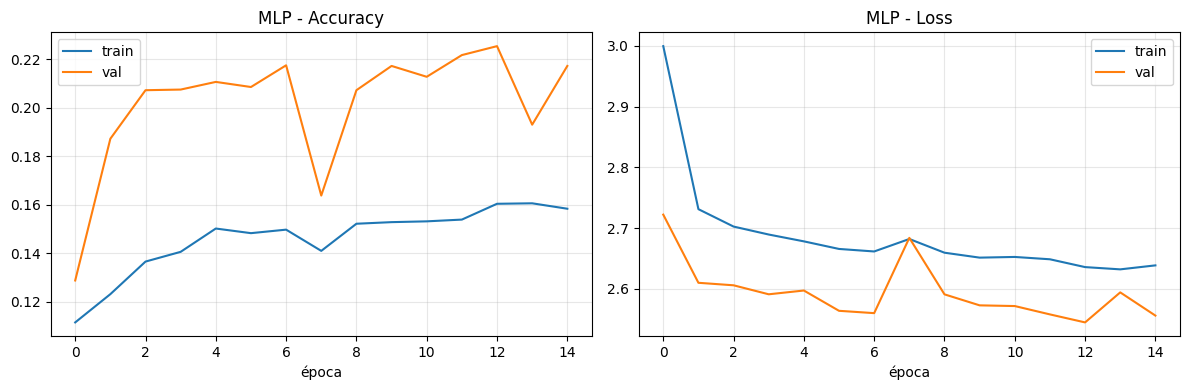

1. MLP (Fully Connected): train=0.2227 | val=0.2172 | test=0.1438


In [ ]:
def build_mlp():
    m = models.Sequential([
        layers.Input(shape=INPUT_SHAPE),
        layers.Flatten(),
        layers.Dense(512, activation="relu"),
        layers.Dropout(0.4),
        layers.Dense(256, activation="relu"),
        layers.Dropout(0.4),
        layers.Dense(NUM_CLASSES, activation="softmax"),
    ], name="MLP")
    m.compile(optimizer=optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

mlp = build_mlp()
mlp.summary()

h_mlp = mlp.fit(X_train, y_train, validation_data=(X_val, y_val),
                epochs=EPOCHS_COMPARE, batch_size=BATCH_SIZE, verbose=2)
graficar_historia(h_mlp, "MLP")
registrar("1. MLP (Fully Connected)", mlp, h_mlp)

## 4. CNN simple

Dos bloques convolucionales con *max pooling* y una capa densa. Sin regularización fuerte.

Model: "CNN_simple"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │     2,097,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 18)             │         2,322 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,118,994 (8.08 MB)

 Trainable params: 2,118,994 (8.08 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
238/238 - 16s - 69ms/step - accuracy: 0.3977 - loss: 2.0037 - val_accuracy: 0.5612 - val_loss: 1.5052
Epoch 2/15
238/238 - 9s - 37ms/step - accuracy: 0.6323 - loss: 1.2659 - val_accuracy: 0.6460 - val_loss: 1.1873
Epoch 3/15
238/238 - 3s - 11ms/step - accuracy: 0.7463 - loss: 0.8814 - val_accuracy: 0.6654 - val_loss: 1.1278
Epoch 4/15
238/238 - 3s - 11ms/step - accuracy: 0.8302 - loss: 0.6039 - val_accuracy: 0.6933 - val_loss: 1.0973
Epoch 5/15
238/238 - 3s - 11ms/step - accuracy: 0.8794 - loss: 0.4197 - val_accuracy: 0.7160 - val_loss: 1.0803
Epoch 6/15
238/238 - 3s - 11ms/step - accuracy: 0.9151 - loss: 0.2916 - val_accuracy: 0.7078 - val_loss: 1.2322
Epoch 7/15
238/238 - 2s - 10ms/step - accuracy: 0.9391 - loss: 0.2041 - val_accuracy: 0.7381 - val_loss: 1.1971
Epoch 8/15
238/238 - 3s - 11ms/step - accuracy: 0.9600 - loss: 0.1303 - val_accuracy: 0.7331 - val_loss: 1.3772
Epoch 9/15
238/238 - 2s - 10ms/step - accuracy: 0.9718 - loss: 0.0996 - val_accuracy: 0.7257 - val_loss

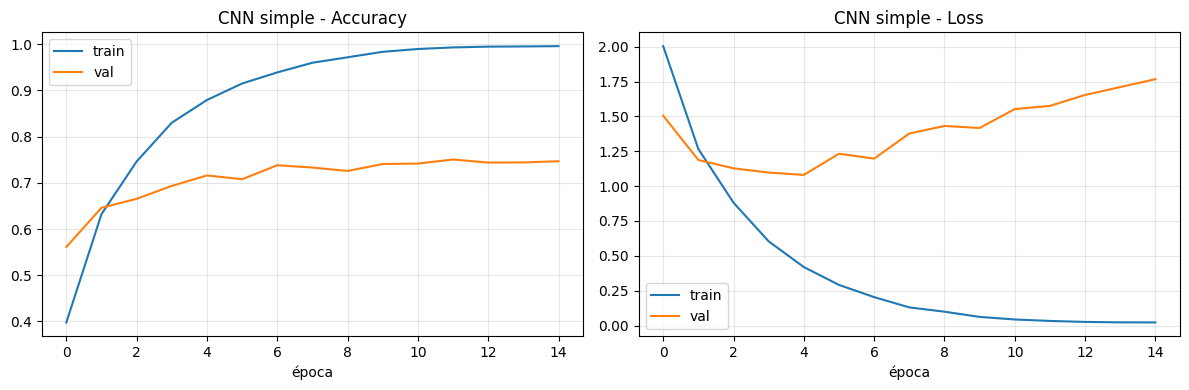

2. CNN simple (2 conv): train=0.9891 | val=0.7468 | test=0.9416


In [ ]:
def build_cnn_simple():
    m = models.Sequential([
        layers.Input(shape=INPUT_SHAPE),
        layers.Conv2D(32, 3, activation="relu", padding="same"),
        layers.MaxPooling2D(),
        layers.Conv2D(64, 3, activation="relu", padding="same"),
        layers.MaxPooling2D(),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dense(NUM_CLASSES, activation="softmax"),
    ], name="CNN_simple")
    m.compile(optimizer=optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

cnn_simple = build_cnn_simple()
cnn_simple.summary()

h_simple = cnn_simple.fit(X_train, y_train, validation_data=(X_val, y_val),
                          epochs=EPOCHS_COMPARE, batch_size=BATCH_SIZE, verbose=2)
graficar_historia(h_simple, "CNN simple")
registrar("2. CNN simple (2 conv)", cnn_simple, h_simple)

## 5. CNN profunda con Batch Normalization y Dropout

Arquitectura tipo VGG: bloques de dos convoluciones 3×3 + `BatchNormalization` + `MaxPooling` + `Dropout`, con cabeza densa regularizada. Probamos primero **sin** data augmentation.

Model: "CNN_profunda_sin_aug"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 16, 16, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 3,283,570 (12.53 MB)

 Trainable params: 3,280,626 (12.51 MB)

 Non-trainable params: 2,944 (11.50 KB)

Epoch 1/15
238/238 - 45s - 190ms/step - accuracy: 0.3759 - loss: 2.1029 - val_accuracy: 0.1687 - val_loss: 2.8173
Epoch 2/15
238/238 - 8s - 33ms/step - accuracy: 0.6269 - loss: 1.1463 - val_accuracy: 0.5238 - val_loss: 1.5905
Epoch 3/15
238/238 - 8s - 33ms/step - accuracy: 0.7345 - loss: 0.7840 - val_accuracy: 0.6741 - val_loss: 1.0917
Epoch 4/15
238/238 - 8s - 33ms/step - accuracy: 0.7879 - loss: 0.6172 - val_accuracy: 0.8228 - val_loss: 0.5978
Epoch 5/15
238/238 - 8s - 33ms/step - accuracy: 0.8284 - loss: 0.4846 - val_accuracy: 0.8063 - val_loss: 0.6675
Epoch 6/15
238/238 - 8s - 34ms/step - accuracy: 0.8580 - loss: 0.4038 - val_accuracy: 0.8692 - val_loss: 0.4625
Epoch 7/15
238/238 - 8s - 34ms/step - accuracy: 0.8707 - loss: 0.3573 - val_accuracy: 0.8592 - val_loss: 0.5053
Epoch 8/15
238/238 - 8s - 34ms/step - accuracy: 0.8876 - loss: 0.3199 - val_accuracy: 0.8805 - val_loss: 0.4458
Epoch 9/15
238/238 - 8s - 34ms/step - accuracy: 0.9031 - loss: 0.2683 - val_accuracy: 0.8676 - val_los

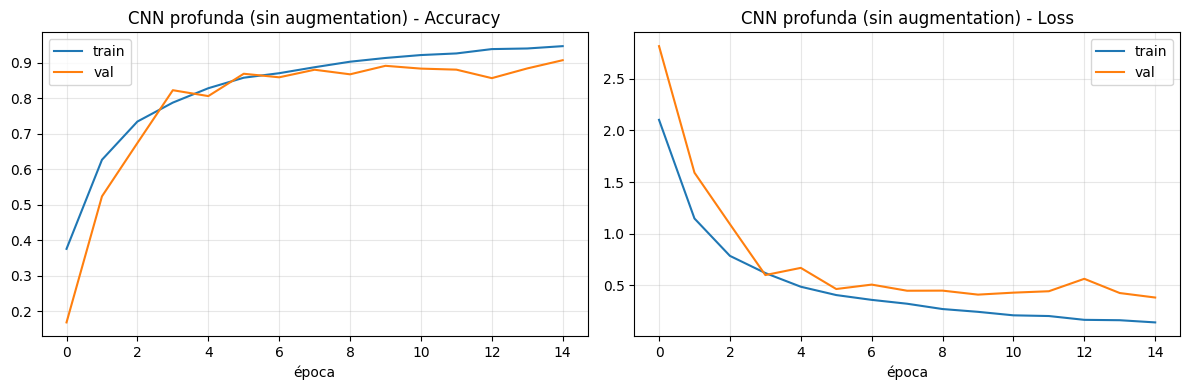

3. CNN profunda + BN + Dropout: train=0.9616 | val=0.9073 | test=0.9483


In [ ]:
def bloque_conv(x, filtros, dropout):
    for _ in range(2):
        x = layers.Conv2D(filtros, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Dropout(dropout)(x)
    return x

def build_cnn_profunda(augment=False, name="CNN_profunda"):
    inp = layers.Input(shape=INPUT_SHAPE)
    x = inp
    if augment:
        # Capas de data augmentation: solo se activan durante el entrenamiento
        x = layers.RandomFlip("horizontal")(x)
        x = layers.RandomRotation(0.08)(x)
        x = layers.RandomZoom(0.15)(x)
        x = layers.RandomTranslation(0.1, 0.1)(x)
    x = bloque_conv(x, 32, 0.20)
    x = bloque_conv(x, 64, 0.25)
    x = bloque_conv(x, 128, 0.30)
    x = bloque_conv(x, 256, 0.35)
    x = layers.Flatten()(x)
    x = layers.Dense(512, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Dropout(0.5)(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    m = models.Model(inp, out, name=name)
    m.compile(optimizer=optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

cnn_deep = build_cnn_profunda(augment=False, name="CNN_profunda_sin_aug")
cnn_deep.summary()

h_deep = cnn_deep.fit(X_train, y_train, validation_data=(X_val, y_val),
                      epochs=EPOCHS_COMPARE, batch_size=BATCH_SIZE,
                      class_weight=CLASS_WEIGHT, verbose=2)
graficar_historia(h_deep, "CNN profunda (sin augmentation)")
registrar("3. CNN profunda + BN + Dropout", cnn_deep, h_deep)

## 6. Modelo final: CNN profunda + Data Augmentation

Se mantiene la misma arquitectura y se agregan transformaciones aleatorias (volteo horizontal, rotación, zoom y traslación) aplicadas sobre la marcha durante el entrenamiento. Esto reduce el overfitting al aumentar la variedad de poses y encuadres.

Callbacks utilizados:
- `ReduceLROnPlateau`: baja el learning rate cuando la `val_loss` se estanca.
- `EarlyStopping`: detiene el entrenamiento y restaura los mejores pesos.
- `ModelCheckpoint`: guarda el mejor modelo en disco.

> Aquí se muestra el **entrenamiento completo** del mejor modelo, como pide el enunciado.

In [ ]:
best_model = build_cnn_profunda(augment=True, name="CNN_profunda_aug")
best_model.summary()

cbs = [
    callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-5, verbose=1),
    callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True, verbose=1),
    callbacks.ModelCheckpoint("mejor_modelo_simpsons.keras", monitor="val_accuracy",
                              save_best_only=True, verbose=0),
]

h_best = best_model.fit(X_train, y_train, validation_data=(X_val, y_val),
                        epochs=EPOCHS_BEST, batch_size=BATCH_SIZE,
                        class_weight=CLASS_WEIGHT, callbacks=cbs, verbose=2)

Model: "CNN_profunda_aug"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 64, 64, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 64, 64, 3)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 64, 64, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_9 (Activation)       │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 64, 64, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_10 (Activation)      │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_11 (Activation)      │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 32, 32, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_12 (Activation)      │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 16, 16, 128)    │        73,72

 Total params: 3,283,570 (12.53 MB)

 Trainable params: 3,280,626 (12.51 MB)

 Non-trainable params: 2,944 (11.50 KB)

Epoch 1/60
238/238 - 27s - 113ms/step - accuracy: 0.2660 - loss: 2.4649 - val_accuracy: 0.0777 - val_loss: 3.1230 - learning_rate: 0.0010
Epoch 2/60
238/238 - 15s - 63ms/step - accuracy: 0.5159 - loss: 1.5177 - val_accuracy: 0.4222 - val_loss: 1.9507 - learning_rate: 0.0010
Epoch 3/60
238/238 - 15s - 62ms/step - accuracy: 0.6341 - loss: 1.1145 - val_accuracy: 0.5562 - val_loss: 1.5331 - learning_rate: 0.0010
Epoch 4/60
238/238 - 15s - 62ms/step - accuracy: 0.7030 - loss: 0.8855 - val_accuracy: 0.7565 - val_loss: 0.8136 - learning_rate: 0.0010
Epoch 5/60
238/238 - 15s - 61ms/step - accuracy: 0.7531 - loss: 0.7343 - val_accuracy: 0.7057 - val_loss: 0.9502 - learning_rate: 0.0010
Epoch 6/60
238/238 - 15s - 62ms/step - accuracy: 0.7811 - loss: 0.6463 - val_accuracy: 0.7515 - val_loss: 0.8118 - learning_rate: 0.0010
Epoch 7/60
238/238 - 15s - 63ms/step - accuracy: 0.8009 - loss: 0.5960 - val_accuracy: 0.8060 - val_loss: 0.6013 - learning_rate: 0.0010
Epoch 8/60
238/238 - 15s - 61ms/step - a

In [ ]:
graficar_historia(h_best, "CNN profunda + augmentation (modelo final)")
registrar("4. CNN profunda + BN + Dropout + Augmentation (FINAL)", best_model, h_best)

## 7. Comparación de modelos

In [ ]:
df_res = pd.DataFrame(resultados).T
df_res["parámetros"] = df_res["parámetros"].astype(int)
for c in ["acc train", "acc val", "acc test"]:
    df_res[c] = (df_res[c] * 100).round(2)
display(df_res)

ax = df_res[["acc train", "acc val", "acc test"]].plot(kind="bar", figsize=(11, 4.5), rot=15)
ax.axhline(85, color="red", ls="--", lw=1, label="meta 85 %")
ax.set_ylabel("Accuracy (%)"); ax.set_title("Comparación de modelos"); ax.legend(loc="lower right")
ax.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.show()

## 8. Evaluación del mejor modelo en el test set

Accuracy global, métricas de *precision*, *recall* y *F1* por clase, y matriz de confusión.

In [ ]:
test_loss, test_acc = best_model.evaluate(X_test, y_test, verbose=0)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_acc*100:.2f}%")
print("¿Cumple la meta de >= 85%?", "SÍ" if test_acc >= 0.85 else "NO")

y_prob = best_model.predict(X_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

print()
print(classification_report(y_test, y_pred, target_names=nombres, digits=3))

In [ ]:
# Precision y recall por clase
prec, rec, f1, sop = precision_recall_fscore_support(y_test, y_pred, labels=np.arange(18), zero_division=0)
df_cls = pd.DataFrame({"personaje": nombres, "precision": prec, "recall": rec, "f1": f1, "soporte": sop})
display(df_cls.sort_values("f1").reset_index(drop=True).round(3))

x = np.arange(18); w = 0.4
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.bar(x - w/2, prec, w, label="precision", color="#4285f4")
ax.bar(x + w/2, rec, w, label="recall", color="#f4b400")
ax.set_xticks(x); ax.set_xticklabels(nombres, rotation=70, ha="right")
ax.set_ylim(0, 1.05); ax.set_title("Precision y recall por personaje (test)")
ax.legend(loc="lower right"); ax.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.show()

In [ ]:
cm = confusion_matrix(y_test, y_pred, labels=np.arange(18))
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(18)); ax.set_yticks(range(18))
ax.set_xticklabels(nombres, rotation=80, ha="right"); ax.set_yticklabels(nombres)
for i, j in itertools.product(range(18), range(18)):
    if cm[i, j] > 0:
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm_norm[i, j] > 0.5 else "black", fontsize=7)
ax.set_xlabel("Predicción"); ax.set_ylabel("Real")
ax.set_title("Matriz de confusión (test) - valores absolutos, color = % por fila")
plt.colorbar(im, fraction=0.046, pad=0.04)
plt.tight_layout(); plt.show()

# Pares de personajes más confundidos
conf = [(nombres[i], nombres[j], cm[i, j]) for i in range(18) for j in range(18) if i != j and cm[i, j] > 0]
conf.sort(key=lambda t: -t[2])
print("Confusiones más frecuentes (real -> predicho):")
for real, pred, n in conf[:8]:
    print(f"  {real:28s} -> {pred:28s} {n}")

## 9. Análisis visual de los errores

Mostramos imágenes de test mal clasificadas, con la clase real, la predicha y la confianza del modelo.

In [ ]:
err_idx = np.where(y_pred != y_test)[0]
print(f"Errores en test: {len(err_idx)} de {len(y_test)} ({100*len(err_idx)/len(y_test):.2f}%)")

# Los errores con mayor confianza son los más "sorprendentes"
err_idx = err_idx[np.argsort(-y_prob[err_idx].max(axis=1))]
n_mostrar = min(24, len(err_idx))

if n_mostrar > 0:
    cols = 6
    filas = int(np.ceil(n_mostrar / cols))
    fig, axes = plt.subplots(filas, cols, figsize=(cols * 2.4, filas * 2.9))
    axes = np.array(axes).reshape(-1)
    for ax in axes: ax.axis("off")
    for k, i in enumerate(err_idx[:n_mostrar]):
        axes[k].imshow(cv2.cvtColor(X_t[i], cv2.COLOR_BGR2RGB))
        axes[k].set_title(f"Real: {nombres[y_test[i]][:14]}\nPred: {nombres[y_pred[i]][:14]}\n({y_prob[i].max()*100:.0f}%)",
                          fontsize=8, color="crimson")
    plt.tight_layout(); plt.show()

In [ ]:
# Errores por clase real
err_por_clase = pd.Series(y_test[y_pred != y_test]).map(MAP_CHARACTERS).value_counts()
print("Errores por personaje (real):")
print(err_por_clase.to_string())

## 10. Conclusiones

Las cifras exactas se ven en las tablas y gráficos de las secciones 7 a 9. Los puntos a comentar en el informe son:

1. **MLP vs CNN**: la red totalmente conectada trata cada píxel de forma independiente, no aprovecha la estructura espacial y tiene muchísimos parámetros en la primera capa, por lo que generaliza peor que las CNN (compárese su accuracy de validación y test en la tabla de la sección 7).
2. **Profundidad y regularización**: pasar de la CNN simple a la CNN profunda con `BatchNormalization` y `Dropout` reduce la brecha entre train y validación y estabiliza el entrenamiento.
3. **Data augmentation**: el volteo, la rotación, el zoom y la traslación aportan variedad de poses y encuadres, lo que ayuda a reducir el overfitting. Se aprecia en las curvas de la sección 6, donde la accuracy de train y de validación se mantienen más cercanas.
4. **Desbalance de clases**: el uso de `class_weight` evita que el modelo favorezca a los personajes con más imágenes, como Homer. El recall y la precisión por clase muestran qué personajes siguen siendo más difíciles.
5. **Errores**: revisar la matriz de confusión y las imágenes mal clasificadas para identificar los personajes que se confunden entre sí (por ejemplo, por parecido de color o de rasgos) y las escenas con varios personajes o con el personaje parcialmente visible.
6. **Resultado vs. meta**: la sección 8 indica explícitamente si el modelo final supera el **85 %** de accuracy exigido en el test set. Recordar que el test set contiene imágenes algo más fáciles que el entrenamiento.

**Posibles mejoras**: usar imágenes de mayor resolución (por ejemplo 96×96 o 128×128), *transfer learning* (MobileNetV2, ResNet50) o *ensembles* de modelos.